# Classificação de animais — HOG + ANOVA F + KNN/SVM

Teste ilustrativo, utilizando 1500 amostras do dataset animals do github.
Acada amostra gera um vetor 1.764 características, gerados por meio da técnica de Histograma de Gradientes Orientados. Para reduzir o vetor de característica de cada amostra, foi utilizado ANOVA para selecionar **50, 100 ou 200 características**. Comparamos os dois classificadores **KNN e SVM** sobre os **mesmos conjuntos**.

**Protocolo:** o seletor, o escalonamento e o classificador são ajustados **somente no treino**. Os seis experimentos (3 dimensões × 2 classificadores) são comparados na **validação**. O **teste é usado apenas uma vez**, depois de escolher a configuração com melhor acurácia de validação. O código está comentado para acompanhamento em aula.


## Roteiro

1. Montar o Google Drive e carregar `knnsvmtest_dividido` (treino, validação, teste).
2. Extrair HOG das 1.500 imagens, sem refazer a divisão.
3. Treinar **KNN e SVM** com `k=50`, `k=100` e `k=200` usando ANOVA F.
4. Comparar os seis resultados de **validação**, escolher o melhor e avaliá-lo no **teste**.
5. Classificar uma imagem individual usando o **pipeline selecionado**.

**Observação:** a ANOVA F pontua cada característica isoladamente pela associação com as classes; não garante melhora da acurácia. Não ajuste as escolhas após observar os resultados de teste.


In [14]:
# ============================================================
# 1. CARREGAMENTO DAS BIBLIOTECAS
# ============================================================
# Path: facilita a criação e a verificação de caminhos de pastas/arquivos.
# NumPy: trabalha com vetores e matrizes numéricas, como os descritores HOG.
# Pandas: organiza os caminhos, classes e conjuntos em uma tabela (DataFrame).
# Matplotlib e Seaborn: criam gráficos e a matriz de confusão.
# random e shutil: ferramentas auxiliares para sorteios e operações com arquivos.
# Neste notebook, random e shutil não são usados nas etapas abaixo; podem ser
# removidos sem afetar o funcionamento atual.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import shutil

# PIL abre as imagens e permite convertê-las para tons de cinza ou RGB.
from PIL import Image

# HOG extrai um vetor que representa os contornos e as orientações dos gradientes.
from skimage.feature import hog

# Importações para preparação de dados e modelos.
# train_test_split não é utilizado porque as pastas já estão divididas em
# treino, validação e teste; não precisamos fazer uma nova divisão aleatória.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Métricas usadas para medir o desempenho do classificador.
from sklearn.metrics import (
    accuracy_score,       # proporção total de previsões corretas
    classification_report,# precisão, recall, F1-score e suporte por classe
    confusion_matrix,     # tabela de classes reais versus classes previstas
    precision_score,      # entre as previsões de uma classe, quantas estavam corretas
    recall_score,         # entre os exemplos reais de uma classe, quantos foram encontrados
    f1_score              # média harmônica entre precisão e recall
)


In [2]:
# ============================================================
# 2. ACESSO AO GOOGLE DRIVE E DEFINIÇÃO DO DATASET
# ============================================================

# Importa a função necessária para conectar o Google Drive ao Colab.
from google.colab import drive
drive.mount('/content/drive')

# Caminho para a pasta que já contém os três conjuntos:
# knnsvmtest_dividido/treino, knnsvmtest_dividido/validacao e
# knnsvmtest_dividido/teste. Não cria nem move imagens nesta etapa.
PASTA_ORIGEM = Path(
    '/content/drive/MyDrive/knnsvmtest_dividido'
)

# Nomes das três classes que o modelo deverá reconhecer.
# Estes nomes devem corresponder exatamente aos nomes das pastas.
CLASSES = ['panda', 'dogs', 'cats']

# Conjuntos definidos previamente: treinamento, validação e teste.
CONJUNTOS = ['treino', 'validacao', 'teste']

# Extensões de arquivo de imagem que serão reconhecidas na busca.
# A comparação será feita sem diferenciar letras maiúsculas/minúsculas.
EXTENSOES = {
    '.jpg', '.jpeg', '.png', '.bmp',
    '.webp', '.jfif', '.tif', '.tiff'
}

# Interrompe a execução com uma mensagem clara se o caminho principal estiver errado.
if not PASTA_ORIGEM.exists():
    raise FileNotFoundError(
        f'Pasta não encontrada: {PASTA_ORIGEM}'
    )

# Confere se cada combinação conjunto/classe existe.
# Exemplo esperado: .../treino/cats, .../validacao/cats e .../teste/cats.
# Essa checagem ajuda a encontrar erros na organização do Drive antes do treino.
for conjunto in CONJUNTOS:
    for classe in CLASSES:
        pasta = PASTA_ORIGEM / conjunto / classe
        if not pasta.exists():
            raise FileNotFoundError(
                f'Pasta esperada não encontrada: {pasta}'
            )

print('Dataset dividido localizado com sucesso!')
print('Pasta:', PASTA_ORIGEM)


Mounted at /content/drive
Dataset dividido localizado com sucesso!
Pasta: /content/drive/MyDrive/knnsvmtest_dividido


In [3]:
# ============================================================
# 3. CRIAÇÃO DE UMA TABELA COM AS IMAGENS
# ============================================================

# rglob('*') percorre recursivamente a pasta de origem e suas subpastas.
# Mantemos apenas arquivos com extensões reconhecidas como imagens.
# sorted() organiza os caminhos para que a ordem seja consistente.
arquivos_divididos = sorted(
    p for p in PASTA_ORIGEM.rglob('*')
    if p.is_file() and p.suffix.lower() in EXTENSOES
)

# Monta um DataFrame (tabela) com uma linha por imagem:
# caminho: endereço completo do arquivo;
# classe: nome da pasta imediatamente acima do arquivo (cats, dogs ou panda);
# conjunto: nome da pasta acima da classe (treino, validacao ou teste).
# Assim, os rótulos reais vêm da organização das pastas, e não de uma previsão.
dados = pd.DataFrame({
    'caminho': [str(p) for p in arquivos_divididos],
    'classe': [p.parent.name for p in arquivos_divididos],
    'conjunto': [p.parent.parent.name for p in arquivos_divididos]
})

# Exibe uma visão geral da quantidade de imagens carregadas.
print(f'Total de imagens: {len(dados)}')
print(f'Total de classes: {dados["classe"].nunique()}')

# Conta quantas imagens pertencem a cada conjunto.
# reindex() garante a exibição na ordem treino, validação e teste;
# fill_value=0 mostra zero caso algum conjunto não tenha imagens.
print('\nQuantidade por conjunto:')
print(dados['conjunto'].value_counts().reindex(CONJUNTOS, fill_value=0))

# Tabela cruzada: linhas = classes; colunas = conjuntos.
# Permite conferir se cada classe tem a quantidade esperada em cada divisão.
print('\nQuantidade por classe e conjunto:')
display(pd.crosstab(dados['classe'], dados['conjunto']).reindex(
    index=CLASSES, columns=CONJUNTOS, fill_value=0
))

# Verificações de consistência. Se algum arquivo estiver faltando ou sobrando,
# a execução para aqui, em vez de produzir métricas com um dataset inesperado.
if len(dados) != 1500:
    raise ValueError(
        f'Esperadas 1500 imagens, mas foram encontradas {len(dados)}.'
    )

# Confere se os nomes das classes são exatamente os definidos acima.
if set(dados['classe'].unique()) != set(CLASSES):
    raise ValueError('As classes encontradas não correspondem às classes esperadas.')

# Quantidades previstas para a divisão 70%/15%/15% de 1500 imagens:
# 1050 para treino, 225 para validação e 225 para teste.
quantidades_esperadas = {'treino': 1050, 'validacao': 225, 'teste': 225}
quantidades_encontradas = dados['conjunto'].value_counts().to_dict()
if quantidades_encontradas != quantidades_esperadas:
    raise ValueError(
        f'Divisão inesperada. Encontrado: {quantidades_encontradas}; '
        f'esperado: {quantidades_esperadas}'
    )

print('\nDataset conferido: 1500 imagens, com divisão 70%/15%/15%.')


Total de imagens: 1500
Total de classes: 3

Quantidade por conjunto:
conjunto
treino       1050
validacao     225
teste         225
Name: count, dtype: int64

Quantidade por classe e conjunto:


conjunto,treino,validacao,teste
classe,,,
panda,350,75,75
dogs,350,75,75
cats,350,75,75



Dataset conferido: 1500 imagens, com divisão 70%/15%/15%.


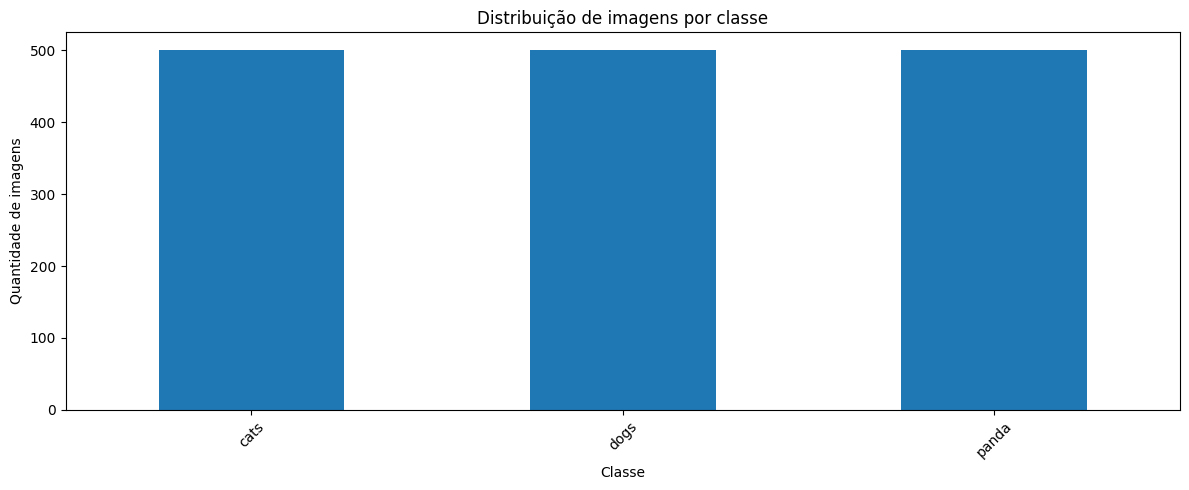

In [4]:
# ============================================================
# 4. VISUALIZAÇÃO DA DISTRIBUIÇÃO DAS CLASSES
# ============================================================

# Cria uma figura com tamanho adequado para o gráfico.
plt.figure(figsize=(12, 5))

# Conta quantas imagens há em cada classe e desenha um gráfico de barras.
# Uma distribuição equilibrada ajuda a comparar as classes de forma mais justa.
dados['classe'].value_counts().plot(kind='bar')

# Adiciona título e nomes dos eixos para facilitar a leitura.
plt.title('Distribuição de imagens por classe')
plt.xlabel('Classe')
plt.ylabel('Quantidade de imagens')

# Gira os rótulos do eixo horizontal para evitar que se sobreponham.
plt.xticks(rotation=45)

# Ajusta os espaços e apresenta o gráfico.
plt.tight_layout()
plt.show()


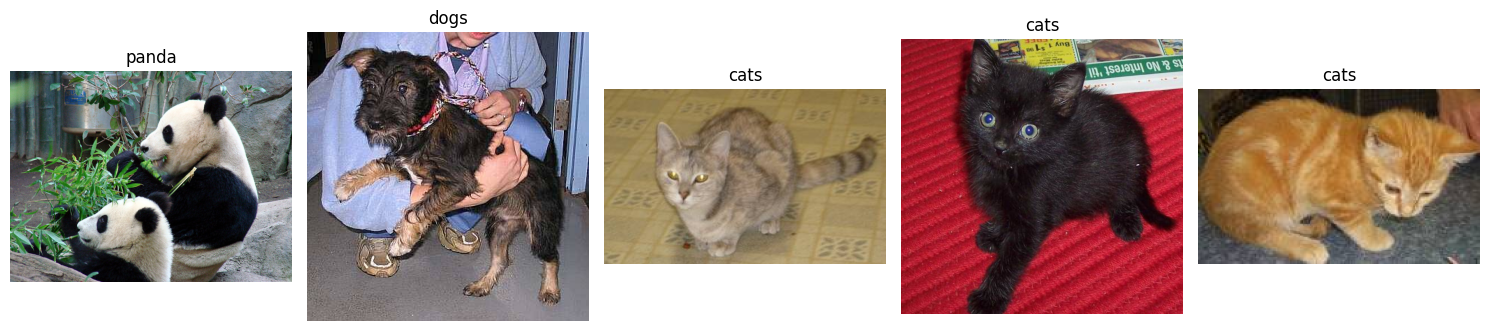

In [5]:
# ============================================================
# 5. VISUALIZAÇÃO DE ALGUMAS IMAGENS DO DATASET
# ============================================================

# Seleciona até cinco imagens para uma inspeção visual rápida.
# random_state=42 faz com que a amostra seja reproduzível entre execuções.
amostra = dados.sample(
    n=min(5, len(dados)),
    random_state=42
)

# Cria uma área de visualização com um painel para cada imagem selecionada.
fig, eixos = plt.subplots(
    1, len(amostra),
    figsize=(15, 4)
)

# Quando existe apenas uma imagem, o Matplotlib pode retornar um único eixo
# em vez de uma lista. Esta condição uniformiza o formato para o loop abaixo.
if len(amostra) == 1:
    eixos = [eixos]

# Percorre as imagens escolhidas e seus respectivos painéis.
for eixo, (_, linha) in zip(eixos, amostra.iterrows()):
    # Abre a imagem e converte para RGB para exibi-la corretamente em cores.
    imagem = Image.open(linha['caminho']).convert('RGB')

    # Mostra a imagem e usa o rótulo obtido da pasta como título.
    eixo.imshow(imagem)
    eixo.set_title(linha['classe'])

    # Oculta as marcações dos eixos, que não são úteis para esta visualização.
    eixo.axis('off')

plt.tight_layout()
plt.show()


In [6]:
# ============================================================
# 6. EXTRAÇÃO DE CARACTERÍSTICAS COM HOG
# ============================================================

def extrair_hog(caminho):
    # Abre a imagem e converte para escala de cinza ('L').
    # HOG trabalha com variações de intensidade; por isso, não precisamos
    # das três componentes de cor RGB nesta implementação.
    imagem = Image.open(caminho).convert('L')

    # Redimensiona todas as imagens para 64 x 64 pixels.
    # Isso garante que cada imagem gere um vetor HOG com o mesmo comprimento.
    imagem = imagem.resize((64, 64))

    # Converte a imagem PIL em uma matriz NumPy de intensidades dos pixels.
    imagem = np.array(imagem)

    # Calcula o Histograma de Gradientes Orientados (HOG).
    caracteristicas = hog(
        imagem,
        orientations=9,            # 9 orientações para os gradientes
        pixels_per_cell=(8, 8),     # cada célula abrange 8 x 8 pixels
        cells_per_block=(2, 2),     # normalização usando blocos de 2 x 2 células
        block_norm='L2-Hys'         # método de normalização dos blocos
    )

    # Retorna um vetor numérico que representa contornos e estrutura visual.
    # Este vetor será a entrada do KNN ou do SVM; não é ainda uma classe.
    return caracteristicas

# Lista que armazenará o vetor HOG correspondente a cada imagem.
X = []

# Percorre todas as imagens da tabela, na mesma ordem usada em 'dados'.
for i, caminho in enumerate(dados['caminho']):
    # Extrai as características da imagem atual.
    caracteristicas = extrair_hog(caminho)
    X.append(caracteristicas)

    # Exibe o progresso a cada 100 imagens para acompanhar a execução.
    if (i + 1) % 100 == 0:
        print(f'Processadas {i + 1} imagens')

# Converte a lista de vetores em uma matriz NumPy.
# Cada linha corresponde a uma imagem; cada coluna, a uma característica HOG.
X = np.array(X)

# Mostra o formato da matriz, por exemplo (1500, número_de_características).
print('Formato da matriz de características:', X.shape)


Processadas 100 imagens
Processadas 200 imagens
Processadas 300 imagens
Processadas 400 imagens
Processadas 500 imagens
Processadas 600 imagens
Processadas 700 imagens
Processadas 800 imagens
Processadas 900 imagens
Processadas 1000 imagens
Processadas 1100 imagens
Processadas 1200 imagens
Processadas 1300 imagens
Processadas 1400 imagens
Processadas 1500 imagens
Formato da matriz de características: (1500, 1764)


In [7]:
# ============================================================
# 7. CODIFICAÇÃO DOS RÓTULOS DAS CLASSES
# ============================================================

# Os classificadores do scikit-learn podem trabalhar com rótulos textuais,
# mas aqui vamos transformar os nomes das classes em números inteiros.
codificador = LabelEncoder()

# Recupera os nomes das classes reais que vieram dos nomes das pastas.
# A ordem dessas classes permanece alinhada à ordem das linhas de X.
y_texto = dados['classe'].values

# Ajusta o codificador às classes encontradas e converte cada nome em um número.
# Por exemplo, cada classe recebe um código inteiro; veja a saída abaixo
# para conferir exatamente qual código corresponde a cada nome.
y = codificador.fit_transform(y_texto)

print('Classes identificadas:')
print(codificador.classes_)


Classes identificadas:
['cats' 'dogs' 'panda']


In [8]:
# ============================================================
# 8. PREPARAÇÃO DOS DADOS E COMPARAÇÃO DE EXPERIMENTOS
# ============================================================

# Os índices são obtidos da tabela; X e y mantêm a mesma ordem das linhas.
indices_treino = dados[dados['conjunto'] == 'treino'].index
indices_val = dados[dados['conjunto'] == 'validacao'].index
indices_teste = dados[dados['conjunto'] == 'teste'].index

X_treino, y_treino = X[indices_treino], y[indices_treino]
X_val, y_val = X[indices_val], y[indices_val]
X_teste, y_teste = X[indices_teste], y[indices_teste]

print(f'Treino: {len(y_treino)} | Validação: {len(y_val)} | Teste: {len(y_teste)}')
print(f'Características HOG originais: {X_treino.shape[1]}')

# Três quantidades de características para comparação.
VALORES_K = [200, 300, 400, 500]

# Avaliamos os DOIS classificadores, mantendo hiperparâmetros fixos.
# Isso permite comparar o efeito da quantidade de características.
CLASSIFICADORES = {
    'KNN': KNeighborsClassifier(n_neighbors=5, metric='euclidean', weights='uniform'),
    'SVM': SVC(kernel='rbf', C=1.0, gamma='scale')
}

resultados = []
modelos_treinados = {}

for nome_tecnica, classificador in CLASSIFICADORES.items():
    for k in VALORES_K:
        # Pipeline: seleção supervisionada -> padronização -> classificador.
        # O SelectKBest aprende quais características são relevantes com
        # base APENAS em X_treino e y_treino (nunca na validação/teste).
        # clone() cria uma instância independente para cada experimento.
        modelo_experimento = Pipeline([
            ('selecao', SelectKBest(score_func=f_classif, k=k)),
            ('scaler', StandardScaler()),
            ('classificador', clone(classificador))
        ])

        # Ajusta os três passos do pipeline somente no treino.
        modelo_experimento.fit(X_treino, y_treino)

        # Aplica automaticamente as mesmas características e escalas
        # ao conjunto de validação (sem reaprender os parâmetros).
        y_pred_val = modelo_experimento.predict(X_val)
        acc_val = accuracy_score(y_val, y_pred_val)
        f1_val = f1_score(y_val, y_pred_val, average='macro', zero_division=0)

        resultados.append({
            'Técnica': nome_tecnica,
            'Features': k,
            'Acurácia validação': acc_val,
            'F1 macro validação': f1_val
        })
        modelos_treinados[(nome_tecnica, k)] = modelo_experimento
        print(f'{nome_tecnica} | k={k:3d} | acurácia validação={acc_val:.4f} | F1={f1_val:.4f}')

# Exibe uma tabela ordenada pela melhor acurácia de validação.
# Em caso de empate, preferimos o maior F1; persistindo, menos features.
tabela_resultados = pd.DataFrame(resultados).sort_values(
    ['Acurácia validação', 'F1 macro validação', 'Features'],
    ascending=[False, False, True]
).reset_index(drop=True)

print('\nCOMPARAÇÃO NA VALIDAÇÃO')
display(tabela_resultados)

# A primeira linha corresponde à configuração escolhida pela validação.
melhor = tabela_resultados.iloc[0]
TECNICA = str(melhor['Técnica'])
NUM_FEATURES = int(melhor['Features'])
modelo = modelos_treinados[(TECNICA, NUM_FEATURES)]

print(f'\nModelo selecionado: {TECNICA} + HOG + ANOVA F (k={NUM_FEATURES})')
print('Índices das características HOG selecionadas (começando em zero):')
print(modelo.named_steps['selecao'].get_support(indices=True))


Treino: 1050 | Validação: 225 | Teste: 225
Características HOG originais: 1764
KNN | k=200 | acurácia validação=0.5200 | F1=0.5196
KNN | k=300 | acurácia validação=0.4667 | F1=0.4669
KNN | k=400 | acurácia validação=0.5378 | F1=0.5292
KNN | k=500 | acurácia validação=0.5156 | F1=0.4947
SVM | k=200 | acurácia validação=0.5911 | F1=0.5926
SVM | k=300 | acurácia validação=0.6133 | F1=0.6155
SVM | k=400 | acurácia validação=0.6133 | F1=0.6150
SVM | k=500 | acurácia validação=0.6089 | F1=0.6103

COMPARAÇÃO NA VALIDAÇÃO


,Técnica,Features,Acurácia validação,F1 macro validação
0,SVM,300,0.613333,0.615457
1,SVM,400,0.613333,0.615026
2,SVM,500,0.608889,0.610297
3,SVM,200,0.591111,0.592622
4,KNN,400,0.537778,0.529185
5,KNN,200,0.520000,0.519627
6,KNN,500,0.515556,0.494690
7,KNN,300,0.466667,0.466894



Modelo selecionado: SVM + HOG + ANOVA F (k=300)
Índices das características HOG selecionadas (começando em zero):
[   1    2    3    4    5    6    7    8   10   11   16   21   25   27
   30   36   37   38   42   43   45   46   47   48   49   52   55   56
   64   72   73   74   75   76   79   81   82   84   85   88   89   91
   92  108  109  111  112  115  116  121  122  123  124  128  137  148
  149  150  151  153  157  158  159  160  161  164  172  173  174  175
  177  178  179  180  184  185  186  187  188  190  194  195  196  197
  199  200  201  204  205  206  213  214  221  222  223  224  226  228
  231  232  233  248  249  253  254  255  256  258  259  262  263  264
  272  273  274  275  276  289  290  291  298  299  316  319  325  326
  335  343  345  346  347  355  362  381  382  383  407  408  409  410
  411  412  413  427  430  431  434  435  438  439  440  447  448  454
  457  458  474  475  478  479  480  481  482  483  484  501  506  507
  508  509  510  523  524  525  5

## Comparação visual das seis configurações

O gráfico abaixo mostra a **acurácia de validação** para cada combinação de técnica e quantidade de características. Ele não utiliza o conjunto de teste.


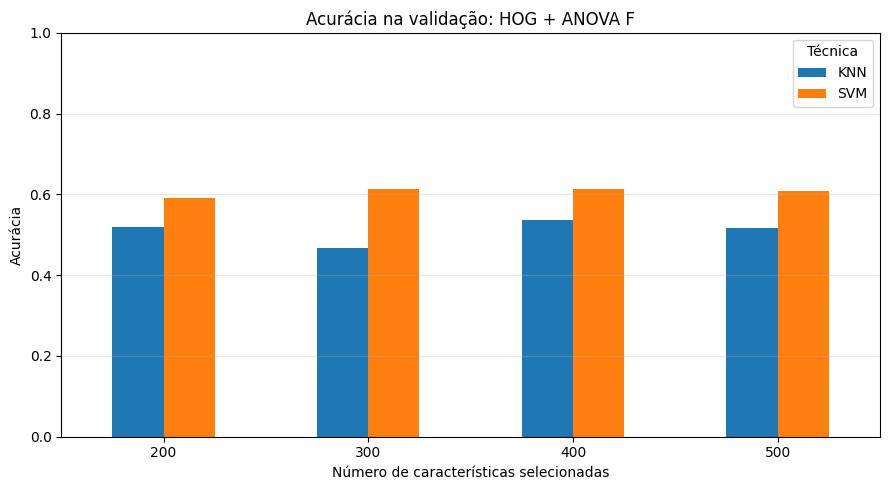

In [9]:
# Gráfico comparativo para discussão em sala.
import matplotlib.pyplot as plt

comparacao = pd.DataFrame(resultados).pivot(
    index='Features', columns='Técnica', values='Acurácia validação'
)
ax = comparacao.plot(kind='bar', figsize=(9, 5), ylim=(0, 1), rot=0)
ax.set_title('Acurácia na validação: HOG + ANOVA F')
ax.set_xlabel('Número de características selecionadas')
ax.set_ylabel('Acurácia')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:
# ============================================================
# 9. AVALIAÇÃO FINAL NO TESTE (SOMENTE DO MODELO ESCOLHIDO)
# ============================================================

# Atenção: o conjunto de teste NÃO participou da escolha do classificador
# nem do número de características. Ele é usado aqui pela primeira vez.
y_pred = modelo.predict(X_teste)

acuracia = accuracy_score(y_teste, y_pred)
precisao = precision_score(y_teste, y_pred, average='macro', zero_division=0)
revocacao = recall_score(y_teste, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_teste, y_pred, average='macro', zero_division=0)

print(f'AVALIAÇÃO FINAL: {TECNICA} + HOG + ANOVA F (k={NUM_FEATURES})')
print(f'Acurácia: {acuracia:.4f}')
print(f'Precisão macro: {precisao:.4f}')
print(f'Recall macro: {revocacao:.4f}')
print(f'F1-score macro: {f1:.4f}')


AVALIAÇÃO FINAL: SVM + HOG + ANOVA F (k=300)
Acurácia: 0.5644
Precisão macro: 0.5638
Recall macro: 0.5644
F1-score macro: 0.5619


In [11]:
# ============================================================
# 10. RELATÓRIO DE CLASSIFICAÇÃO
# ============================================================

# classification_report resume o desempenho para cada classe:
# precision: entre as previsões daquela classe, quantas estavam corretas;
# recall: entre as imagens reais daquela classe, quantas foram identificadas;
# f1-score: equilíbrio entre precision e recall;
# support: quantidade de exemplos reais daquela classe no conjunto de teste.
#
# y_teste contém os códigos das classes reais e y_pred contém os códigos previstos.
# labels fixa a ordem dos códigos e target_names mostra os nomes legíveis.
# zero_division=0 evita avisos e retorna zero quando uma métrica não pode
# ser calculada por ausência de previsões para alguma classe.
print(
    classification_report(
        y_teste,
        y_pred,
        labels=np.arange(len(codificador.classes_)),
        target_names=codificador.classes_,
        zero_division=0
    )
)


              precision    recall  f1-score   support

        cats       0.55      0.45      0.50        75
        dogs       0.52      0.57      0.54        75
       panda       0.62      0.67      0.65        75

    accuracy                           0.56       225
   macro avg       0.56      0.56      0.56       225
weighted avg       0.56      0.56      0.56       225



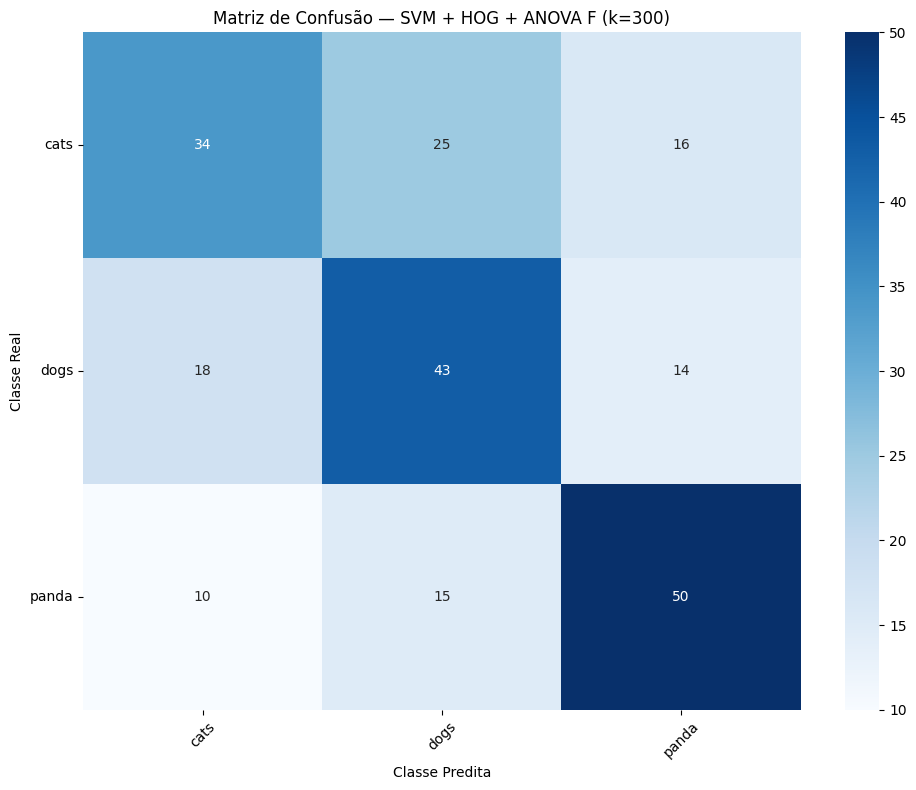

In [12]:
# ============================================================
# 11. MATRIZ DE CONFUSÃO
# ============================================================

# Compara as classes reais (linhas) com as classes previstas (colunas).
# Cada célula informa quantas imagens de uma classe real foram previstas
# como pertencentes à classe indicada na coluna.
matriz = confusion_matrix(
    y_teste,
    y_pred,
    labels=np.arange(len(codificador.classes_))
)

# Cria a figura onde será desenhado o mapa de calor.
plt.figure(figsize=(10, 8))

# annot=True escreve os números nas células; fmt='d' usa números inteiros.
# cmap='Blues' define a paleta; os nomes das classes aparecem nos eixos.
sns.heatmap(
    matriz,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=codificador.classes_,
    yticklabels=codificador.classes_
)

# As células da diagonal principal representam acertos.
# Os valores fora da diagonal representam confusões entre classes.
plt.title(f'Matriz de Confusão — {TECNICA.upper()} + HOG + ANOVA F (k={NUM_FEATURES})')
plt.xlabel('Classe Predita')
plt.ylabel('Classe Real')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:
# ============================================================
# 12. CLASSIFICAÇÃO DE UMA IMAGEM INDIVIDUAL (TESTE OFF-LINE)
# ============================================================

# Informe o caminho de uma imagem que deseja classificar.
# Troque este endereço por um arquivo que realmente exista no seu Google Drive.
# A imagem não precisa estar acompanhada de um rótulo para que o modelo faça
# uma previsão; o rótulo real só é necessário depois, caso queira avaliar se
# a previsão estava correta.
caminho_imagem = '/content/drive/MyDrive/test_animals/cats/cats_00019.jpg'

# Extrai HOG da imagem usando exatamente a mesma função aplicada ao dataset:
# escala de cinza, redimensionamento para 64 x 64 e os mesmos parâmetros HOG.
caracteristicas = extrair_hog(caminho_imagem)

# O modelo foi treinado com uma matriz em que cada linha é uma imagem.
# reshape(1, -1) transforma o vetor da imagem em uma matriz com 1 linha
# e tantas colunas quantas forem as características HOG.
caracteristicas = caracteristicas.reshape(1, -1)

# O pipeline primeiro reduz de 1764 para NUM_FEATURES características,
# depois padroniza e faz a previsão. Não selecione manualmente aqui.
# predict() estima a classe com base no padrão aprendido durante o treinamento.
# Ele não consulta nem descobre o rótulo verdadeiro da imagem.
predicao = modelo.predict(caracteristicas)

# A previsão está codificada numericamente; inverse_transform converte o código
# novamente para o nome da classe, como 'cats', 'dogs' ou 'panda'.
classe_predita = codificador.inverse_transform(predicao)[0]

# Exibe o algoritmo usado e a classe que o modelo estimou.
print(f'Técnica utilizada: {TECNICA.upper()} + HOG + ANOVA F (k={NUM_FEATURES})')
print('Classe prevista:', classe_predita)

# Importante: para medir se esta previsão está correta, é preciso conhecer
# o rótulo real por outra fonte e compará-lo com classe_predita.


Técnica utilizada: SVM + HOG + ANOVA F (k=300)
Classe prevista: cats
